In [1]:
# %pip install pandas

In [218]:
import re
from datetime import datetime

import pandas as pd


### Задание 1
#### Этап 1

In [219]:
class Account:
    start = 1000
    account_type = ''

    def __init__(self, owner, balance=0):
        if balance < 0:
            raise ValueError (f'Отрицательный баланс: {balance}')

        if not re.fullmatch(r'[A-ZА-Я][a-zа-я]* [A-ZА-Я][a-zа-я]*', owner):
            raise ValueError(f'Недопустимое имя: {owner}')

        self.owner = owner
        self.balance = balance
        self.account_number = f'ACC-{Account.start}'
        Account.start += 1
        self.history = []

    def update(self, operation, amount, status):
        self.history.append({
            'account_number': self.account_number,
            'account_type': self.account_type,
            'date': datetime.now(),
            'operation': operation,
            'amount': amount,
            'balance_after': self.balance,
            'status': status
        })

    def deposit(self, amount, operation='deposit'):
        if amount <= 0:
            raise ValueError(f'Недопустимая сумма: {amount}')

        self.balance += amount
        self.update(operation, amount, 'success')

    def withdraw(self, amount, operation='withdraw'):
        if amount <= 0:
            raise ValueError(f'Недопустимая сумма: {amount}')

        if amount > self.balance:
            self.update(operation, amount, 'fail')
            return

        self.balance -= amount
        self.update(operation, amount, 'success')


In [222]:
# проверка
try:
  account_ivanov = Account('Ivan Ivanov', 10000)

  account_ivanov.withdraw(20000)
  account_ivanov.withdraw(100)
  account_ivanov.deposit(1000)
  account_ivanov.deposit(-2000)
except ValueError as err:
  print(err)
finally:
  print(f'Баланс: {account_ivanov.balance}')
  print(account_ivanov.history)


Недопустимая сумма: -2000
Баланс: 10900
[{'account_number': 'ACC-1001', 'account_type': '', 'date': datetime.datetime(2026, 10, 23, 16, 52, 51, 241574), 'operation': 'withdraw', 'amount': 20000, 'balance_after': 10000, 'status': 'fail'}, {'account_number': 'ACC-1001', 'account_type': '', 'date': datetime.datetime(2026, 10, 23, 16, 52, 51, 241581), 'operation': 'withdraw', 'amount': 100, 'balance_after': 9900, 'status': 'success'}, {'account_number': 'ACC-1001', 'account_type': '', 'date': datetime.datetime(2026, 10, 23, 16, 52, 51, 241585), 'operation': 'deposit', 'amount': 1000, 'balance_after': 10900, 'status': 'success'}]


In [223]:
account_ivanov.withdraw(5000)

In [224]:
account_ivanov.deposit(1200)

In [225]:
account_ivanov.withdraw(4000)

#### Этап 2

<Axes: xlabel='date'>

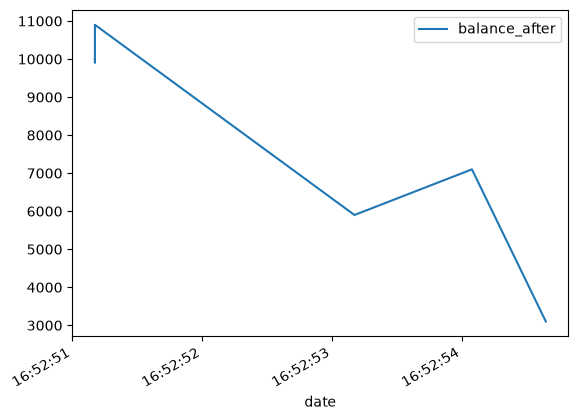

In [226]:
df = pd.DataFrame(account_ivanov.history)
df.plot(x='date', y='balance_after')

### Задание 2. Разные типы счетов и аналитика


In [227]:
class AccountChecking(Account):
    account_type = 'checking'


class AccountSavings(Account):
    account_type = 'savings'

    def raise_interest_rate(self, rate):
        if rate < 0:
            raise ValueError(f'Недопустимая ставка: {rate}')

        amount = self.balance * rate / 100
        self.balance += amount
        self.update('interest', amount, 'success')

    def withdraw(self, amount, operation='withdraw'):
        if amount > 0 and amount > self.balance * 0.5:
            self.update(operation, amount, 'fail')
            return
        super().withdraw(amount, operation)

In [228]:
def get_history(self, N, threshold):
    result = []

    for e in self.history:
        if e['status'] == 'success' and e['amount'] >= threshold:
            result.append(e)

    return result[-N:]

Account.get_history = get_history


In [229]:
try:
    checking_ivanov = AccountChecking('Ivan Ivanov', 10000)
    savings_petrov = AccountSavings('Petr Petrov', 20000)

    print(checking_ivanov.account_type, checking_ivanov.balance)
    print(savings_petrov.account_type, savings_petrov.balance, '\n')

    # начисление %
    savings_petrov.raise_interest_rate(7)
    # превышение 50% сбережений
    savings_petrov.withdraw(15000)

    print(savings_petrov.account_type, savings_petrov.balance, '\n')

    # получение истории
    print(savings_petrov.get_history(3, 100), '\n')

    AccountChecking('ivan Pupkin', 1000)
except ValueError as err:
    print(err)

checking 10000
savings 20000 

savings 21400.0 

[{'account_number': 'ACC-1003', 'account_type': 'savings', 'date': datetime.datetime(2026, 10, 23, 16, 53, 14, 524267), 'operation': 'interest', 'amount': 1400.0, 'balance_after': 21400.0, 'status': 'success'}] 

Недопустимое имя: ivan Pupkin


In [230]:
def transfer(self, recipient, amount):
    if amount <= 0:
        raise ValueError(f'Недопустимая сумма: {amount}')

    self.withdraw(amount, 'transfer')

    if self.history[-1]['status'] == 'success':
        recipient.deposit(amount, 'transfer')
        # поле - transfer_recipient как идентификатор исходящего перевода
        self.history[-1]['transfer_recipient'] = recipient.account_number
        # поле - transfer_sender как идентификатор входящего перевода
        recipient.history[-1]['transfer_sender'] = self.account_number

Account.transfer = transfer

In [231]:
savings_petrov.transfer(checking_ivanov, 200)

In [232]:
print(savings_petrov.balance)
print(checking_ivanov.balance)
print(savings_petrov.history[-1])
print(checking_ivanov.history[-1])

21200.0
10200
{'account_number': 'ACC-1003', 'account_type': 'savings', 'date': datetime.datetime(2026, 10, 23, 16, 53, 25, 926602), 'operation': 'transfer', 'amount': 200, 'balance_after': 21200.0, 'status': 'success', 'transfer_recipient': 'ACC-1002'}
{'account_number': 'ACC-1002', 'account_type': 'checking', 'date': datetime.datetime(2026, 10, 23, 16, 53, 25, 926615), 'operation': 'transfer', 'amount': 200, 'balance_after': 10200, 'status': 'success', 'transfer_sender': 'ACC-1003'}


### Задание 3. Загрузка «грязных» данных

In [265]:
df_csv = pd.read_csv('transactions_dirty.csv')
display(df_csv.head())
df_csv.isna().sum()

,account_number,account_type,date,operation,amount,balance_after,status
0,ACC-100001,checking,2025-09-27 22:17:26,deposit,921.0,2121.0,success
1,ACC-100001,checking,2025-09-27 22:17:26,deposit,607.0,2728.0,success
2,ACC-100001,checking,2025-09-28 22:17:26,deposit,488.0,3216.0,success
3,ACC-100001,checking,28/09/2025 22:17,deposit,129.0,3345.0,success
4,ACC-100001,checking,2025-09-29 22:17:26,deposit,880.0,4225.0,success


account_number    0
account_type      0
date              0
operation         2
amount            3
balance_after     0
status            0
dtype: int64

In [266]:
df_json = pd.read_json('transactions_dirty.json')
display(df_json.head())
df_json.isna().sum()

,account_number,account_type,date,operation,amount,balance_after,status
0,ACC-100001,checking,2025-09-27 22:17:26,deposit,921.0,2121.0,success
1,ACC-100001,checking,2025-09-27 22:17:26,deposit,607.0,2728.0,success
2,ACC-100001,checking,2025-09-28 22:17:26,deposit,488.0,3216.0,success
3,ACC-100001,checking,28/09/2025 22:17,deposit,129.0,3345.0,success
4,ACC-100001,checking,2025-09-29 22:17:26,deposit,880.0,4225.0,success


account_number    0
account_type      0
date              0
operation         2
amount            3
balance_after     0
status            0
dtype: int64

In [270]:
def load_history(self, df):
    operations = ['deposit', 'withdraw', 'transfer']
    if self.account_type == 'savings':
        operations.append('interest')

    df = df[(df['account_number'] == self.account_number) &
            (df['account_type'] == self.account_type)]

    for i, row in df.iterrows():
        op = row['operation']
        amount = row['amount']
        status = row['status']
        date = pd.to_datetime(
            row['date'],
            format='mixed',
            dayfirst=True,
            errors='coerce'
        )

        if op not in operations or pd.isna(op):
            print(i, 'Неверная операция:', op)
            continue
        if pd.isna(amount) or amount <= 0:
            print(i, 'Неверная сумма:', amount)
            continue
        if pd.isna(date):
            print(i, 'Неверная дата:', row['date'])
            continue
        if status not in ['success', 'fail']:
            print(i, 'Неверный статус:', status)
            continue

        if status == 'success':
            if op == 'transfer':
                sender = row.get('transfer_sender')
                recipient = row.get('transfer_recipient')

                if sender == self.account_number:
                    direction = 'out'
                elif recipient == self.account_number:
                    direction = 'in'
                else:
                    print(i, 'Неизвестно направление перевода')
                    continue

            elif op == 'withdraw':
                direction = 'out'
            else:
                direction = 'in'

            if direction == 'out':
                if amount > self.balance:
                    print(i, 'Недостаточно средств')
                    continue
                if self.account_type == 'savings' and amount > self.balance / 2:
                    print(i, 'Превышен лимит 50%')
                    continue
                self.balance -= amount
            else:
                self.balance += amount

        history = row.to_dict()
        history['date'] = date
        history['balance_after'] = self.balance
        self.history.append(history)

Account.load_history = load_history

In [271]:
checking_kozlov = AccountChecking('Ivan Kozlov', 12000)
checking_kozlov.account_number = 'ACC-100001'

savings_pupkin = AccountSavings('Вася Пупкин', 500)
savings_pupkin.account_number = 'ACC-100004'

In [272]:
checking_kozlov.load_history(df_csv)
savings_pupkin.load_history(df_csv)

5 Неверная сумма: nan
8 Неверная операция: nan
10 Неверная операция: interest
13 Неверная дата: 2025-17-34 12:00:00
15 Неверная операция: diposit
16 Неверная операция: interest
17 Неверная дата: 2023-16-40 12:00:00
24 Неверный статус: succes
70 Неверная операция: diposit
73 Неверный статус: succes
77 Неверная сумма: -459.0
79 Неверный статус: succes
80 Неверный статус: succes
84 Неверная сумма: nan
86 Неверная дата: 2024-17-35 12:00:00
90 Неверный статус: succes
93 Неверная сумма: -307.0
94 Неверная дата: 2025-16-35 12:00:00
98 Неверная операция: nan


In [275]:
checking_kozlov.history

[{'account_number': 'ACC-100001',
  'account_type': 'checking',
  'date': Timestamp('2025-09-27 22:17:26'),
  'operation': 'deposit',
  'amount': 921.0,
  'balance_after': 12921.0,
  'status': 'success'},
 {'account_number': 'ACC-100001',
  'account_type': 'checking',
  'date': Timestamp('2025-09-27 22:17:26'),
  'operation': 'deposit',
  'amount': 607.0,
  'balance_after': 13528.0,
  'status': 'success'},
 {'account_number': 'ACC-100001',
  'account_type': 'checking',
  'date': Timestamp('2025-09-28 22:17:26'),
  'operation': 'deposit',
  'amount': 488.0,
  'balance_after': 14016.0,
  'status': 'success'},
 {'account_number': 'ACC-100001',
  'account_type': 'checking',
  'date': Timestamp('2025-09-28 22:17:00'),
  'operation': 'deposit',
  'amount': 129.0,
  'balance_after': 14145.0,
  'status': 'success'},
 {'account_number': 'ACC-100001',
  'account_type': 'checking',
  'date': Timestamp('2025-09-29 22:17:26'),
  'operation': 'deposit',
  'amount': 880.0,
  'balance_after': 15025.0,

In [276]:
savings_pupkin.history

[{'account_number': 'ACC-100004',
  'account_type': 'savings',
  'date': Timestamp('2025-09-23 22:17:26'),
  'operation': 'deposit',
  'amount': 192.0,
  'balance_after': 692.0,
  'status': 'success'},
 {'account_number': 'ACC-100004',
  'account_type': 'savings',
  'date': Timestamp('2025-09-23 22:17:26'),
  'operation': 'deposit',
  'amount': 662.0,
  'balance_after': 1354.0,
  'status': 'success'},
 {'account_number': 'ACC-100004',
  'account_type': 'savings',
  'date': Timestamp('2025-09-24 22:17:26'),
  'operation': 'deposit',
  'amount': 649.0,
  'balance_after': 2003.0,
  'status': 'success'},
 {'account_number': 'ACC-100004',
  'account_type': 'savings',
  'date': Timestamp('2025-09-25 22:17:26'),
  'operation': 'deposit',
  'amount': 276.0,
  'balance_after': 2279.0,
  'status': 'success'},
 {'account_number': 'ACC-100004',
  'account_type': 'savings',
  'date': Timestamp('2025-09-25 22:17:26'),
  'operation': 'deposit',
  'amount': 126.0,
  'balance_after': 2405.0,
  'status'